# Bài 2. Đánh giá YOLOv4 và YOLO26n trong bài toán phát hiện đối tượng

- Họ và tên: Nguyễn Đăng Thới Toàn
- MSHV: 25C15062

## Nội dung thực hiện

- So sánh YOLOv4 và YOLO26n trên COCO val2017 bằng mAP, Precision và Recall.
- Đánh giá robustness trong điều kiện ánh sáng yếu, che khuất và vật thể nhỏ.
- Benchmark tốc độ suy luận (latency, FPS) và trực quan hóa kết quả.
- Fine-tuning YOLO26n trên Chess Pieces Dataset và phân tích kết quả huấn luyện.

## 1. Môi trường và quy ước thực nghiệm

Chạy notebook bằng kernel của môi trường ảo có PyTorch CUDA, CUDA Toolkit (`nvcc`) và các gói sau. Cài gói trong terminal của môi trường ảo trước khi mở kernel:

```bash
python -m pip install -U ultralytics pycocotools opencv-python matplotlib pandas ipykernel imageio-ffmpeg
```

PyTorch bản CUDA nên được cài theo [hướng dẫn chính thức](https://pytorch.org/get-started/locally/) phù hợp driver và GPU. Notebook chỉ bỏ qua bước biên dịch nếu tìm thấy dấu xác nhận của chính lần build GPU trước đó trên cùng kiến trúc; lần đầu cần `nvcc`.

- Tập kiểm thử: COCO 2017 validation. Đánh giá chất lượng trên toàn bộ 5.000 ảnh COCO val2017 (`MAX_IMAGES = None`). Các thí nghiệm ảnh tối/che khuất dùng 60 ảnh được lấy mẫu bằng seed cố định; đo tốc độ dùng 50 ảnh. mAP@0.5 trên ảnh sạch do COCOeval tính từ đủ tập validation.
- Đầu vào: 608 × 608; YOLOv4 dùng phép resize của Darknet, YOLO26n dùng letterbox của Ultralytics. Cùng kích thước danh nghĩa nhưng cách tiền xử lý khác nhau.
- Hậu xử lý: ngưỡng confidence 0,001 cho AP; NMS IoU 0,45; tối đa 100 box/ảnh. Precision/Recall điểm hoạt động dùng confidence 0,25, IoU khớp 0,5.
- Thiết bị: GPU duy nhất, batch = 1, FP32 mặc định. 

### Import thư viện và thiết lập đường dẫn

Cell tiếp theo tạo `ROOT`, `DATA`, `DARKNET` và các tham số dùng xuyên suốt bài. Hãy chạy cell này trước các cell dữ liệu và mô hình.


In [1]:
import ctypes as ct
import os
import random
import shutil
import subprocess
import sys
import tempfile
import time
import urllib.request
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from IPython.display import Video, display
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm import tqdm
from ultralytics import YOLO

ROOT = Path.cwd().resolve()
DATA = ROOT / "data_bai2"
DARKNET = ROOT / "darknet"
MAX_IMAGES = None  # dùng toàn bộ 5.000 ảnh COCO val2017
STRESS_IMAGES = 60  # cùng số ảnh cho mỗi phép biến dạng
SEED = 2026
IMG_SIZE = 608
NMS_IOU = 0.45
AP_CONF = 0.001
PR_CONF = 0.25
MAX_DET = 100
BENCH_IMAGES = 50
WARMUP = 10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert torch.cuda.is_available(), "Bài đo này yêu cầu PyTorch nhận GPU CUDA."
DATA.mkdir(exist_ok=True)
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "| CUDA:", torch.version.cuda)
print("Ultralytics:", ultralytics.__version__)

GPU: NVIDIA GeForce RTX 5090
PyTorch: 2.7.0+cu128 | CUDA: 12.8
Ultralytics: 8.4.189


## 2. Dữ liệu COCO val2017

Tải ảnh và nhãn gốc từ bucket COCO qua HTTPS của Amazon S3. Hai mô hình đều được huấn luyện trước trên COCO; tập validation tách khỏi tập train của bộ dữ liệu. Toàn bộ 5.000 ảnh validation được sử dụng cho đánh giá ảnh sạch; seed chỉ dùng khi chọn nhóm ảnh cho thí nghiệm điều kiện bất lợi. Lần chạy đầu cần khoảng 1 GB để tải ảnh và thêm dung lượng để giải nén.

In [2]:
def download_and_extract(url, filename, marker, expected_count=None):
    archive = DATA / filename

    def is_complete():
        return marker.exists() and (
            expected_count is None
            or sum(1 for _ in marker.parent.glob("*.jpg")) == expected_count
        )

    if is_complete():
        print(f"Đã có dữ liệu: {filename}")
        return

    if not archive.exists():
        print(f"Downloading {filename}...")
        tmp = archive.with_suffix(".tmp")
        try:
            with urllib.request.urlopen(url, timeout=60) as response, \
                 open(tmp, "wb") as f, \
                 tqdm.wrapattr(
                     f, "write",
                     total=int(response.headers.get("Content-Length", 0)) or None,
                     desc=filename, unit="B", unit_scale=True
                 ) as output:
                shutil.copyfileobj(response, output)
            tmp.replace(archive)
        finally:
            tmp.unlink(missing_ok=True)

    print(f"Extracting {filename}...")
    with zipfile.ZipFile(archive) as zf:
        zf.extractall(DATA)

    assert is_complete(), f"Dữ liệu chưa đầy đủ: {filename}"
    print(f"Done: {filename}")


# Download COCO 2017 validation data
download_and_extract("https://s3.amazonaws.com/images.cocodataset.org/zips/val2017.zip", "val2017.zip", DATA / "val2017/000000000139.jpg", expected_count=5000,)
download_and_extract("https://s3.amazonaws.com/images.cocodataset.org/annotations/annotations_trainval2017.zip", "annotations_trainval2017.zip", DATA / "annotations/instances_val2017.json")

# Load COCO annotations and sample images
coco = COCO(str(DATA / "annotations/instances_val2017.json"))
all_ids = sorted(coco.getImgIds())

rng = np.random.default_rng(SEED)
image_ids = sorted(rng.choice(all_ids, MAX_IMAGES, replace=False)) if MAX_IMAGES else all_ids

print(f"Evaluation images: {len(image_ids)}/{len(all_ids)}")
print("Sample IDs:", image_ids[:8])

Đã có dữ liệu: val2017.zip
Đã có dữ liệu: annotations_trainval2017.zip
loading annotations into memory...
Done (t=0.30s)
creating index...
index created!
Evaluation images: 5000/5000
Sample IDs: [139, 285, 632, 724, 776, 785, 802, 872]


## 3. Nạp hai mô hình đã huấn luyện

YOLOv4 chạy qua thư viện `libdarknet.so` của [AlexeyAB/darknet](https://github.com/AlexeyAB/darknet) biên dịch với `GPU=1`; YOLO26n dùng trọng số `yolo26n.pt` trong [Ultralytics](https://docs.ultralytics.com/models/yolo26/). Notebook sẽ tải trọng số YOLOv4 nếu chưa có. Khi biên dịch Darknet, mã sử dụng compute capability do PyTorch báo cho GPU hiện tại; CUDA Toolkit phải hỗ trợ kiến trúc đó.

In [3]:
# 1. Clone Darknet
if not (DARKNET / "Makefile").exists():
    subprocess.run(
        ["git", "clone", "https://github.com/AlexeyAB/darknet.git", str(DARKNET)],
        check=True,
    )

# 2. Build Darknet for GPU (only when needed)
os.environ["PATH"] = "/usr/local/cuda/bin:" + os.environ["PATH"]

sm = "".join(map(str, torch.cuda.get_device_capability(0)))
stamp = DARKNET / ".gpu_build"
lib = DARKNET / "libdarknet.so"

if not lib.exists() or not stamp.exists() or stamp.read_text() != sm:
    assert shutil.which("nvcc"), "CUDA Toolkit (nvcc) not found"

    for cmd in [
        ["make", "clean"],
        ["make", "-j4", "GPU=1", "CUDNN=0", "LIBSO=1",
         f"ARCH=-gencode arch=compute_{sm},code=sm_{sm}"],
    ]:
        result = subprocess.run(cmd, cwd=DARKNET, capture_output=True, text=True)
        if result.returncode:
            raise RuntimeError(result.stdout[-3000:] + result.stderr[-3000:])

    assert lib.exists(), "Darknet build failed"
    stamp.write_text(sm)
    print(f"Darknet compiled for GPU sm_{sm}")

# 3. Download pretrained YOLOv4 weights
weights = DARKNET / "yolov4.weights"
url = "https://github.com/AlexeyAB/darknet/releases/download/darknet_yolo_v4_pre/yolov4.weights"

if not weights.exists() or weights.stat().st_size != 257_717_640:
    tmp = weights.with_suffix(".tmp")
    try:
        urllib.request.urlretrieve(url, tmp)
        assert tmp.stat().st_size == 257_717_640, "Incomplete weights"
        tmp.replace(weights)
    finally:
        tmp.unlink(missing_ok=True)

# 4. Load YOLOv4 and YOLO26n
sys.path.insert(0, str(DARKNET))
import darknet

cwd = Path.cwd()
try:
    os.chdir(DARKNET)
    network, darknet_names, _ = darknet.load_network(
        "cfg/yolov4.cfg", "cfg/coco.data", str(weights)
    )
finally:
    os.chdir(cwd)

assert darknet.network_width(network) == darknet.network_height(network) == IMG_SIZE

model26 = YOLO("yolo26n.pt").to("cuda:0")
assert len(darknet_names) == len(model26.names) == 80

print("YOLOv4 and YOLO26n loaded successfully on GPU")

 Try to load cfg: cfg/yolov4.cfg, weights: /workspace/workspace/lt/darknet/yolov4.weights, clear = 0 
net.optimized_memory = 0 
mini_batch = 1, batch = 8, time_steps = 1, train = 0 
Create CUDA-stream - 0 


 0 : compute_capability = 1200, cudnn_half = 0, GPU: NVIDIA GeForce RTX 5090 
   layer   filters  size/strd(dil)      input                output
   0 conv     32       3 x 3/ 1    608 x 608 x   3 ->  608 x 608 x  32 0.639 BF
   1 conv     64       3 x 3/ 2    608 x 608 x  32 ->  304 x 304 x  64 3.407 BF
   2 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   3 route  1 		                           ->  304 x 304 x  64 
   4 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   5 conv     32       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  32 0.379 BF
   6 conv     64       3 x 3/ 1    304 x 304 x  32 ->  304 x 304 x  64 3.407 BF
   7 Shortcut Layer: 4,  wt = 0, wn = 0, outputs: 304 x 304 x  64 0.006 BF
   8 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   9 route  8 2 	                           ->  304 x 304 x 128 
  10 conv     64       1 x 1/ 1    304 x 304 x 128 ->  304 x 304 x  64 1.514 BF
  11 conv 

nms_kind: greedynms (1), beta = 0.600000 
nms_kind: greedynms (1), beta = 0.600000 


conv    512       3 x 3/ 1     38 x  38 x 256 ->   38 x  38 x 512 3.407 BF
 147 conv    256       1 x 1/ 1     38 x  38 x 512 ->   38 x  38 x 256 0.379 BF
 148 conv    512       3 x 3/ 1     38 x  38 x 256 ->   38 x  38 x 512 3.407 BF
 149 conv    255       1 x 1/ 1     38 x  38 x 512 ->   38 x  38 x 255 0.377 BF
 150 yolo
[yolo] params: iou loss: ciou (4), iou_norm: 0.07, obj_norm: 1.00, cls_norm: 1.00, delta_norm: 1.00, scale_x_y: 1.10
 151 route  147 		                           ->   38 x  38 x 256 
 152 conv    512       3 x 3/ 2     38 x  38 x 256 ->   19 x  19 x 512 0.852 BF
 153 route  152 116 	                           ->   19 x  19 x1024 
 154 conv    512       1 x 1/ 1     19 x  19 x1024 ->   19 x  19 x 512 0.379 BF
 155 conv   1024       3 x 3/ 1     19 x  19 x 512 ->   19 x  19 x1024 3.407 BF
 156 conv    512       1 x 1/ 1     19 x  19 x1024 ->   19 x  19 x 512 0.379 BF
 157 conv   1024       3 x 3/ 1     19 x  19 x 512 ->   19 x  19 x1024 3.407 BF
 158 conv    512       

nms_kind: greedynms (1), beta = 0.600000 
 Try to load weights: /workspace/workspace/lt/darknet/yolov4.weights 

 seen 64, trained: 32032 K-images (500 Kilo-batches_64) 
Loaded - names_list: data/coco.names, classes = 80 
YOLOv4 and YOLO26n loaded successfully on GPU


Done! Loaded 162 layers from weights-file 


### Chuẩn hóa lớp và bounding box

Hai thư viện trả dự đoán theo định dạng khác nhau. Mỗi hàm bên dưới chuyển kết quả thành `{class_id, score, xyxy}` ở hệ tọa độ của ảnh gốc. Ánh xạ 80 lớp COCO liên tục sang ID danh mục COCO gốc được kiểm tra trước khi tính chỉ số. Darknet wrapper mặc định làm tròn score; vì vậy phần phát hiện YOLOv4 ở đây gọi API thấp hơn để giữ score dạng số thực đầy đủ.

In [4]:
# 1. COCO class mapping (80 indices -> category IDs)
COCO80_TO_ID = coco.getCatIds()
assert len(COCO80_TO_ID) == 80
assert darknet_names[0] == model26.names[0] == "person"
assert darknet_names[2] == model26.names[2] == "car"


# 2. Read COCO image
def read_image(image_id):
    filename = coco.loadImgs(image_id)[0]["file_name"]
    image = cv2.imread(str(DATA / "val2017" / filename))
    if image is None:
        raise FileNotFoundError(filename)
    return image


# 3. YOLOv4 inference (Darknet)
def infer_yolov4(image):
    h, w = image.shape[:2]
    rgb = cv2.cvtColor(
        cv2.resize(image, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_BGR2RGB
    )
    img = darknet.make_image(IMG_SIZE, IMG_SIZE, 3)

    try:
        darknet.copy_image_from_bytes(img, rgb.tobytes())
        darknet.predict_image(network, img)

        count = ct.pointer(ct.c_int(0))
        raw = darknet.get_network_boxes(
            network, IMG_SIZE, IMG_SIZE, AP_CONF, 0.5, None, 0, count, 0
        )
        try:
            darknet.do_nms_sort(raw, count[0], 80, NMS_IOU)
            detections = []

            for det in raw[:count[0]]:
                b = det.bbox
                box = (
                    (b.x - b.w / 2) * w / IMG_SIZE,
                    (b.y - b.h / 2) * h / IMG_SIZE,
                    (b.x + b.w / 2) * w / IMG_SIZE,
                    (b.y + b.h / 2) * h / IMG_SIZE,
                )
                detections.extend(
                    (cls, float(det.prob[cls]), box)
                    for cls in range(80)
                    if det.prob[cls] >= AP_CONF
                )
        finally:
            darknet.free_detections(raw, count[0])
    finally:
        darknet.free_image(img)

    return sorted(detections, key=lambda x: -x[1])[:MAX_DET]


# 4. YOLO26n inference (Ultralytics)
def infer_yolo26n(image):
    result = model26.predict(
        image, imgsz=IMG_SIZE, device=0,
        conf=AP_CONF, iou=NMS_IOU,
        max_det=MAX_DET, verbose=False,
    )[0]

    if result.boxes is None:
        return []

    return [
        (int(cls), float(conf), tuple(map(float, box)))
        for box, conf, cls in zip(
            result.boxes.xyxy.cpu().numpy(),
            result.boxes.conf.cpu().numpy(),
            result.boxes.cls.cpu().numpy(),
        )
    ]


INFER = {"YOLOv4": infer_yolov4, "YOLO26n": infer_yolo26n}
print("COCO mapping and inference functions ready")

COCO mapping and inference functions ready


## 4. Giao thức đánh giá

mAP@0.5 tính bằng `pycocotools.COCOeval` trên toàn bộ 80 lớp, IoU = 0,5, tối đa 100 dự đoán mỗi ảnh. Precision/Recall là micro-average tại score ≥ 0,25: ghép một dự đoán với tối đa một nhãn thật cùng lớp nếu IoU ≥ 0,5; vùng `iscrowd` không được tính như một false positive. Vì cách tổng hợp khác nhau, Precision/Recall ở một ngưỡng score không thể suy ra trực tiếp từ mAP.

Điều kiện ánh sáng yếu và che khuất là ảnh biến đổi nhân tạo, giữ nguyên nhãn. Phần che khuất đặt hình chữ nhật lên giữa vật thể lớn nhất của mỗi ảnh; cách này kiểm tra mức suy giảm do che một phần chứ không mô phỏng mọi tình huống thực tế. Nhóm "nhiều vật thể nhỏ" được lấy mẫu cố định từ các ảnh có ít nhất ba nhãn với diện tích gốc nhỏ hơn 32x32 pixel; cột `AP50_small` chỉ đánh giá các vật thể nhỏ theo chuẩn diện tích COCO.

In [5]:
def clip_xyxy(box, width, height):
    x1, y1, x2, y2 = box
    return (
        max(0.0, min(float(x1), width)),
        max(0.0, min(float(y1), height)),
        max(0.0, min(float(x2), width)),
        max(0.0, min(float(y2), height)),
    )


def to_coco_results(image_id, detections, image):
    height, width = image.shape[:2]
    rows = []
    for cls, score, box in detections:
        x1, y1, x2, y2 = clip_xyxy(box, width, height)
        if x2 <= x1 or y2 <= y1:
            continue
        rows.append(
            {
                "image_id": int(image_id),
                "category_id": COCO80_TO_ID[cls],
                "bbox": [x1, y1, x2 - x1, y2 - y1],
                "score": score,
            }
        )
    return rows


def bbox_iou(a, b):
    xx1, yy1 = max(a[0], b[0]), max(a[1], b[1])
    xx2, yy2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0, xx2 - xx1) * max(0, yy2 - yy1)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    return intersection / (area_a + area_b - intersection + 1e-12)


def xywh_to_xyxy(box):
    x, y, w, h = box
    return (x, y, x + w, y + h)


def count_matches(image_id, detections):
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[int(image_id)]))
    ordinary = [ann for ann in anns if not ann.get("iscrowd", 0)]
    crowd = [ann for ann in anns if ann.get("iscrowd", 0)]
    matched = set()
    tp = fp = 0
    for cls, score, box in sorted(detections, key=lambda p: p[1], reverse=True):
        if score < PR_CONF:
            continue
        cat_id = COCO80_TO_ID[cls]
        candidates = [
            (bbox_iou(box, xywh_to_xyxy(ann["bbox"])), idx)
            for idx, ann in enumerate(ordinary)
            if idx not in matched and ann["category_id"] == cat_id
        ]
        best_iou, best_idx = max(candidates, default=(0, -1))
        if best_iou >= 0.5:
            matched.add(best_idx)
            tp += 1
        elif not any(
            ann["category_id"] == cat_id
            and bbox_iou(box, xywh_to_xyxy(ann["bbox"])) >= 0.5
            for ann in crowd
        ):
            fp += 1
    return tp, fp, len(ordinary) - tp


def ap_metrics(image_ids_for_case, result_rows):
    if not result_rows:
        return 0.0, 0.0
    result_coco = coco.loadRes(result_rows)
    evaluator = COCOeval(coco, result_coco, "bbox")
    evaluator.params.imgIds = list(map(int, image_ids_for_case))
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()
    ap50 = float(evaluator.stats[1])
    precision = evaluator.eval["precision"][0, :, :, 1, 2]
    valid = precision[precision >= 0]
    ap50_small = float(valid.mean()) if valid.size else float("nan")
    return ap50, ap50_small

### Tạo các điều kiện và chạy hai mô hình trên cùng ảnh

`clean_stress` là nhóm ảnh sạch dùng làm mốc riêng cho điều kiện ánh sáng yếu và che khuất. Nhờ vậy, mức suy giảm không bị nhầm với khác biệt do chọn ảnh. Mỗi kết quả dùng cùng một tập nhãn COCO gốc; không dùng nhãn sinh từ mô hình.

In [6]:
def low_light(image):
    return np.clip(image.astype(np.float32) * 0.35, 0, 255).astype(np.uint8)


def occlude(image, image_id):
    altered = image.copy()
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[int(image_id)], iscrowd=False))
    if not anns:
        return altered
    target = max(anns, key=lambda ann: ann["area"])
    x, y, width, height = target["bbox"]
    cx, cy = x + width / 2, y + height / 2
    half_w, half_h = 0.28 * width, 0.28 * height
    x1, y1, x2, y2 = clip_xyxy(
        (cx - half_w, cy - half_h, cx + half_w, cy + half_h),
        altered.shape[1],
        altered.shape[0],
    )
    cv2.rectangle(
        altered, (int(x1), int(y1)), (int(x2), int(y2)), (40, 40, 40), thickness=-1
    )
    return altered


def small_count(image_id):
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[int(image_id)], iscrowd=False))
    return sum(ann["area"] < 32**2 for ann in anns)


stress_candidates = [
    image_id
    for image_id in image_ids
    if coco.getAnnIds(imgIds=[int(image_id)], iscrowd=False)
]
small_candidates = [image_id for image_id in image_ids if small_count(image_id) >= 3]
stress_ids = sorted(
    np.random.default_rng(SEED + 1)
    .choice(
        stress_candidates,
        size=min(STRESS_IMAGES, len(stress_candidates)),
        replace=False,
    )
    .tolist()
)
small_ids = sorted(
    np.random.default_rng(SEED + 2)
    .choice(
        small_candidates, size=min(STRESS_IMAGES, len(small_candidates)), replace=False
    )
    .tolist()
)
assert stress_ids and small_ids, "Hãy tăng MAX_IMAGES để có đủ ảnh nhiều vật thể nhỏ"
CASES = {
    "Ảnh sạch": (image_ids, lambda image, image_id: image),
    "Sạch / nhóm stress": (stress_ids, lambda image, image_id: image),
    "Ánh sáng yếu": (stress_ids, lambda image, image_id: low_light(image)),
    "Che khuất": (stress_ids, occlude),
    "Nhiều vật thể nhỏ": (small_ids, lambda image, image_id: image),
}
print({name: len(ids) for name, (ids, _) in CASES.items()})

{'Ảnh sạch': 5000, 'Sạch / nhóm stress': 60, 'Ánh sáng yếu': 60, 'Che khuất': 60, 'Nhiều vật thể nhỏ': 60}


In [7]:
records = []
all_predictions = {}
for case_name, (case_ids, transform) in CASES.items():
    for model_name, infer in INFER.items():
        result_rows = []
        tp = fp = fn = 0
        prediction_cache = {}
        for position, image_id in enumerate(case_ids, start=1):
            image = transform(read_image(image_id), image_id)
            if case_name in ("Sạch / nhóm stress", "Nhiều vật thể nhỏ"):
                detections = all_predictions[("Ảnh sạch", model_name)][image_id]
            else:
                detections = infer(image)
            prediction_cache[image_id] = detections
            result_rows.extend(to_coco_results(image_id, detections, image))
            a, b, c = count_matches(image_id, detections)
            tp, fp, fn = tp + a, fp + b, fn + c
            if position % 500 == 0 or position == len(case_ids):
                print(f"{case_name} / {model_name}: {position}/{len(case_ids)} ảnh")
        ap50, ap50_small = ap_metrics(case_ids, result_rows)
        records.append(
            {
                "Điều kiện": case_name,
                "Mô hình": model_name,
                "Số ảnh": len(case_ids),
                "mAP@0.5": ap50,
                "AP50_small": ap50_small,
                "Precision@0.25": tp / max(tp + fp, 1),
                "Recall@0.25": tp / max(tp + fn, 1),
            }
        )
        all_predictions[(case_name, model_name)] = prediction_cache
        print(f"Xong: {case_name} / {model_name}")

quality = pd.DataFrame(records)
display(quality.round(4))

Ảnh sạch / YOLOv4: 500/5000 ảnh
Ảnh sạch / YOLOv4: 1000/5000 ảnh
Ảnh sạch / YOLOv4: 1500/5000 ảnh
Ảnh sạch / YOLOv4: 2000/5000 ảnh
Ảnh sạch / YOLOv4: 2500/5000 ảnh
Ảnh sạch / YOLOv4: 3000/5000 ảnh
Ảnh sạch / YOLOv4: 3500/5000 ảnh
Ảnh sạch / YOLOv4: 4000/5000 ảnh
Ảnh sạch / YOLOv4: 4500/5000 ảnh
Ảnh sạch / YOLOv4: 5000/5000 ảnh
Loading and preparing results...
DONE (t=0.60s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=9.88s).
Accumulating evaluation results...
DONE (t=1.72s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.504
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.748
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.557
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.356
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.559
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | m

,Điều kiện,Mô hình,Số ảnh,mAP@0.5,AP50_small,Precision@0.25,Recall@0.25
0,Ảnh sạch,YOLOv4,5000,0.7477,0.5930,0.7061,0.7134
1,Ảnh sạch,YOLO26n,5000,0.5554,0.3180,0.7800,0.4848
2,Sạch / nhóm stress,YOLOv4,60,0.7589,0.6488,0.6445,0.6610
3,Sạch / nhóm stress,YOLO26n,60,0.5808,0.4070,0.7926,0.4037
4,Ánh sáng yếu,YOLOv4,60,0.7520,0.6669,0.6703,0.6371
5,Ánh sáng yếu,YOLO26n,60,0.5664,0.4059,0.7766,0.3850
6,Che khuất,YOLOv4,60,0.5945,0.5998,0.5676,0.5724
7,Che khuất,YOLO26n,60,0.4488,0.3244,0.6856,0.3492
8,Nhiều vật thể nhỏ,YOLOv4,60,0.6987,0.6102,0.6277,0.6741
9,Nhiều vật thể nhỏ,YOLO26n,60,0.5173,0.4188,0.7778,0.3987


### Mức suy giảm chất lượng

Với mỗi điều kiện, lấy đúng nhóm ảnh sạch làm mốc. Hiệu tuyệt đối là `ΔmAP = mAP_sạch − mAP_biến_dạng` trên thang 0-1. Mức thay đổi tương đối là `ΔmAP / mAP_sạch × 100%`. Giá trị dương nghĩa là hiệu năng giảm; giá trị âm nghĩa là hiệu năng tăng. Nhóm chỉ có 60 ảnh nên các chênh lệch này chưa phản ánh độ bất định thống kê.


,Mô hình,Điều kiện,Giảm mAP@0.5 (Δ),Giảm tương đối (%)
0,YOLOv4,Ánh sáng yếu,0.01,0.91
1,YOLOv4,Che khuất,0.16,21.66
2,YOLO26n,Ánh sáng yếu,0.01,2.49
3,YOLO26n,Che khuất,0.13,22.74


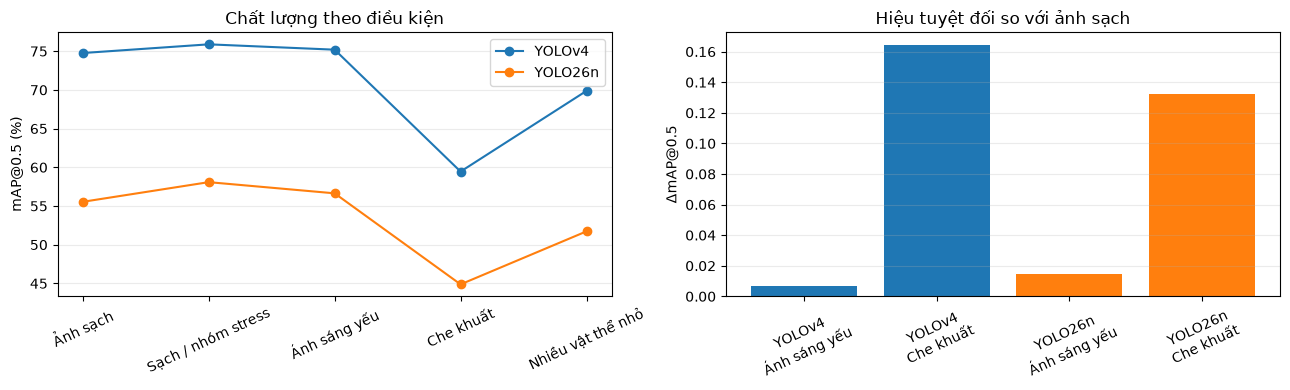

In [8]:
degradation = []
for model_name in INFER:
    reference = quality.query(
        '`Điều kiện` == "Sạch / nhóm stress" and `Mô hình` == @model_name'
    ).iloc[0]
    for condition in ("Ánh sáng yếu", "Che khuất"):
        target = quality.query(
            "`Điều kiện` == @condition and `Mô hình` == @model_name"
        ).iloc[0]
        delta = reference["mAP@0.5"] - target["mAP@0.5"]
        degradation.append(
            {
                "Mô hình": model_name,
                "Điều kiện": condition,
                "Giảm mAP@0.5 (Δ)": delta,
                "Giảm tương đối (%)": 100 * delta / max(reference["mAP@0.5"], 1e-12),
            }
        )
degradation = pd.DataFrame(degradation)
display(degradation.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for model_name in INFER:
    subset = quality[quality["Mô hình"] == model_name]
    axes[0].plot(
        subset["Điều kiện"], 100 * subset["mAP@0.5"], marker="o", label=model_name
    )
    subset_deg = degradation[degradation["Mô hình"] == model_name]
    axes[1].bar(
        [f"{model_name}\n{v}" for v in subset_deg["Điều kiện"]],
        subset_deg["Giảm mAP@0.5 (Δ)"],
        label=model_name,
    )
axes[0].set(ylabel="mAP@0.5 (%)", title="Chất lượng theo điều kiện")
axes[1].set(ylabel="ΔmAP@0.5", title="Hiệu tuyệt đối so với ảnh sạch")
for axis in axes:
    axis.tick_params(axis="x", rotation=25)
    axis.grid(axis="y", alpha=0.25)
axes[0].legend()
plt.tight_layout()
plt.show()

## 5. Đo độ trễ và FPS trên GPU

Đo cùng các ảnh sạch đã chọn, lần lượt chạy từng mô hình; có warm-up để loại ảnh hưởng khởi tạo. Số `FPS = số ảnh / tổng thời gian suy luận`, batch = 1. Thời gian bao gồm chuyển dữ liệu lên/xuống GPU khi thư viện thực hiện. Tốc độ này phụ thuộc GPU, driver, CUDA, precision, phương thức tiền xử lý và batch size; không dùng để so sánh trực tiếp với bảng benchmark ở phần cứng khác.

In [9]:
benchmark_ids = image_ids[: min(BENCH_IMAGES, len(image_ids))]
benchmark_images = [read_image(image_id) for image_id in benchmark_ids]
speed_rows = []
for model_name, infer in INFER.items():
    for image in benchmark_images[: min(WARMUP, len(benchmark_images))]:
        infer(image)
    torch.cuda.synchronize()
    times_ms = []
    for image in benchmark_images:
        torch.cuda.synchronize()
        started = time.perf_counter()
        infer(image)
        torch.cuda.synchronize()
        times_ms.append(1000 * (time.perf_counter() - started))
    speed_rows.append(
        {
            "Mô hình": model_name,
            "Số ảnh": len(times_ms),
            "Latency TB (ms)": np.mean(times_ms),
            "Latency trung vị (ms)": np.median(times_ms),
            "Latency p95 (ms)": np.percentile(times_ms, 95),
            "FPS": 1000 * len(times_ms) / sum(times_ms),
        }
    )
speed = pd.DataFrame(speed_rows)
display(speed.round(2))

,Mô hình,Số ảnh,Latency TB (ms),Latency trung vị (ms),Latency p95 (ms),FPS
0,YOLOv4,50,11.72,9.7,21.39,85.34
1,YOLO26n,50,3.09,3.1,3.21,323.24


## 6. Minh họa dự đoán cạnh nhau


COCO image ID: 7511


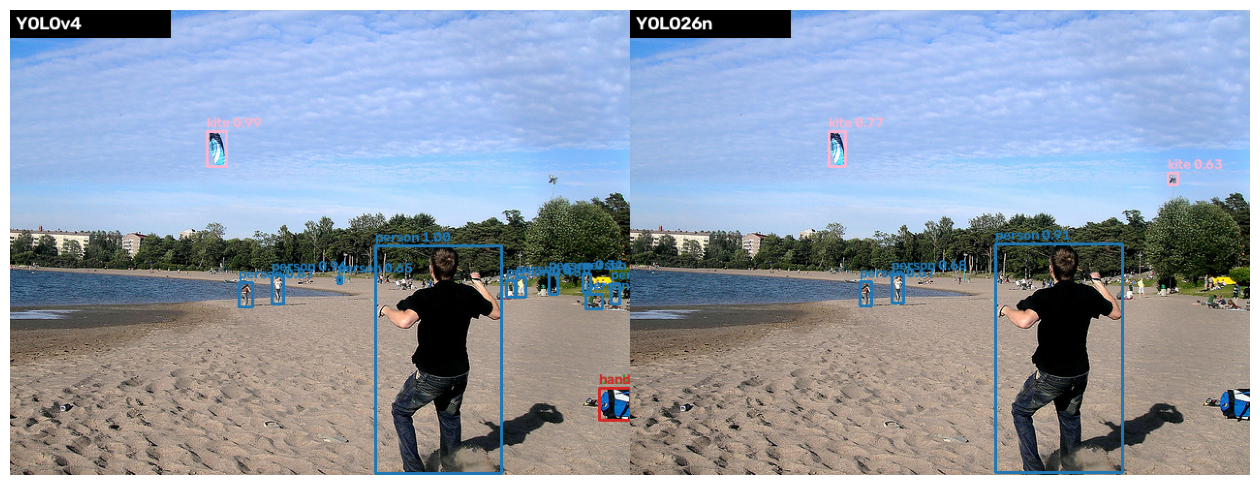

In [10]:
def draw_detections(image, detections, title, score_limit=PR_CONF):
    canvas = image.copy()
    height, width = canvas.shape[:2]
    for cls, score, box in detections:
        if score < score_limit:
            continue
        x1, y1, x2, y2 = map(int, clip_xyxy(box, width, height))
        color = tuple(int(255 * v) for v in plt.cm.tab20(cls % 20)[:3][::-1])
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, 2)
        label = f"{coco.cats[COCO80_TO_ID[cls]]['name']} {score:.2f}"
        cv2.putText(
            canvas,
            label,
            (x1, max(16, y1 - 4)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.48,
            color,
            2,
            cv2.LINE_AA,
        )
    cv2.rectangle(canvas, (0, 0), (min(width, 165), 28), (0, 0, 0), -1)
    cv2.putText(
        canvas,
        title,
        (6, 20),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.62,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )
    return canvas


def side_by_side(image, predictions):
    left = draw_detections(image, predictions["YOLOv4"], "YOLOv4")
    right = draw_detections(image, predictions["YOLO26n"], "YOLO26n")
    return np.concatenate([left, right], axis=1)


IMAGE_PATH = None  # Ví dụ: Path("anh_cua_toi.jpg")
if IMAGE_PATH is None:
    demo_image_id = small_ids[0]
    demo_image = read_image(demo_image_id)
    demo_predictions = {
        name: all_predictions[("Ảnh sạch", name)][demo_image_id] for name in INFER
    }
    print("COCO image ID:", demo_image_id)
else:
    demo_image = cv2.imread(str(IMAGE_PATH))
    if demo_image is None:
        raise FileNotFoundError(IMAGE_PATH)
    demo_predictions = {name: infer(demo_image) for name, infer in INFER.items()}
    print("Ảnh riêng:", IMAGE_PATH)
comparison = side_by_side(demo_image, demo_predictions)
plt.figure(figsize=(16, 7))
plt.imshow(cv2.cvtColor(comparison, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

### Demo video




In [11]:
import imageio_ffmpeg

VIDEO_PATH = ROOT / "14620692_1280_720_30fps.mp4" 
VIDEO_SECONDS = 3
FRAME_SIZE = (640, 360)  
OUTPUT_VIDEO = ROOT / "so_sanh_yolo_h264.mp4"

if VIDEO_PATH is None:
    source_fps = 4.0
    frame_limit = 12
    source_frames = (read_image(image_id) for image_id in image_ids[:frame_limit])
else:
    source = cv2.VideoCapture(str(VIDEO_PATH))
    if not source.isOpened():
        raise FileNotFoundError(f"Không mở được video: {VIDEO_PATH}")
    source_fps = source.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(source_fps) or source_fps <= 0:
        source.release()
        raise ValueError("Không đọc được FPS của video đầu vào")
    total_frames = int(source.get(cv2.CAP_PROP_FRAME_COUNT))
    requested_frames = (
        total_frames if VIDEO_SECONDS is None else round(source_fps * VIDEO_SECONDS)
    )
    frame_limit = (
        min(total_frames, requested_frames) if total_frames > 0 else requested_frames
    )

    def read_video_frames():
        try:
            for _ in range(frame_limit):
                ok, frame = source.read()
                if not ok:
                    break
                yield frame
        finally:
            source.release()

    source_frames = read_video_frames()

output_size = (FRAME_SIZE[0] * 2, FRAME_SIZE[1])
encoder = imageio_ffmpeg.write_frames(
    OUTPUT_VIDEO,
    size=output_size,
    fps=source_fps,
    codec="libx264",
    pix_fmt_in="rgb24",
    pix_fmt_out="yuv420p",
    macro_block_size=8,
    quality=7,
    ffmpeg_log_level="error",
    output_params=["-movflags", "+faststart"],
)
frame_count = 0
try:
    encoder.send(None)
    for frame in source_frames:
        resized = cv2.resize(frame, FRAME_SIZE, interpolation=cv2.INTER_AREA)
        predictions = {name: infer(resized) for name, infer in INFER.items()}
        side_image = side_by_side(resized, predictions)
        rgb_image = cv2.cvtColor(side_image, cv2.COLOR_BGR2RGB)
        encoder.send(rgb_image.tobytes())
        frame_count += 1
finally:
    encoder.close()
    if VIDEO_PATH is not None:
        source.release()

if frame_count == 0 or not OUTPUT_VIDEO.exists() or OUTPUT_VIDEO.stat().st_size == 0:
    raise RuntimeError("Không tạo được video đầu ra")
print(
    f"Đã xử lý {frame_count} khung hình ở {source_fps:.2f} FPS "
    f"({frame_count / source_fps:.1f} giây)."
)
print("Video H.264 đã lưu tại:", OUTPUT_VIDEO)
display(Video(str(OUTPUT_VIDEO), embed=True, html_attributes="controls"))

Đã xử lý 90 khung hình ở 29.97 FPS (3.0 giây).
Video H.264 đã lưu tại: /workspace/workspace/lt/so_sanh_yolo_h264.mp4


## 7. Fine-tuning YOLO26 Nano trên Chess Pieces Dataset

Do YOLOv4 sử dụng Darknet, một framework tương đối cũ, việc huấn luyện trên GPU NVIDIA RTX 5090 gặp nhiều hạn chế về khả năng tương thích và tối ưu hiệu năng. Vì vậy, em lựa chọn YOLO26 Nano (YOLO26n)để thực hiện phần mở rộng fine-tuning.

Mô hình được huấn luyện trên Chess Pieces Dataset từ Roboflow trong 50 epochs có Early Stopping, nhằm phát hiện và phân loại các quân cờ. Sau huấn luyện, mô hình được đánh giá bằng Precision, Recall, mAP@0.5 và mAP@0.5:0.95, đồng thời trực quan hóa kết quả dự đoán trên tập test.

### Train

In [ ]:
%pip install -q roboflow ultralytics

from roboflow import Roboflow
from ultralytics import YOLO

ROOT = Path.cwd()

rf = Roboflow(api_key="YOUR_API_KEY") # DELETE API KEY BERE PUSH CODE
dataset = rf.workspace("joseph-nelson").project("chess-pieces-new").version(23).download("yolov8")
DATASET = Path(dataset.location).resolve()
DATA_YAML = DATASET / "data.yaml"

print("Dataset:", DATASET)

Note: you may need to restart the kernel to use updated packages.
loading Roboflow workspace...
loading Roboflow project...
Dataset: /workspace/workspace/lt/Chess-Pieces-23


In [24]:
import pandas as pd
from IPython.display import display

model = YOLO("yolo26n.pt")

model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=416,
    batch=16,
    device=0,
    workers=4,
    patience=10,
    project=str(ROOT / "runs"),
    name="chess_yolo26n",
    exist_ok=True,
    plots=True,
)

model = YOLO(str(ROOT / "runs/chess_yolo26n/weights/best.pt"))

metrics = model.val(data=str(DATA_YAML), split="val", imgsz=416, device=0)

rows = [
    ["all", metrics.box.mp, metrics.box.mr, metrics.box.map50, metrics.box.map]
]

for i, cls in enumerate(metrics.box.ap_class_index):
    rows.append([model.names[int(cls)], *metrics.box.class_result(i)])

df = pd.DataFrame(
    rows,
    columns=["Class", "Precision", "Recall", "mAP50", "mAP50-95"]
)

display(df.round(3))
print("Training completed!")

Ultralytics 8.4.189 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/workspace/lt/Chess-Pieces-23/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=chess_yolo26n, nbs=64, nms=

Transferred 696/708 items from pretrained weights
AMP: running Automatic Mixed Precision (AMP) checks...
AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 10402.3±2446.0 MB/s, size: 269.3 KB)
train: Scanning /workspace/workspace/lt/Chess-Pieces-23/train/labels.cache... 202 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 202/202 60.5Mit/s 0.0s
train: /workspace/workspace/lt/Chess-Pieces-23/train/images/26d663ab5ffbec49f9dc8e592982cfd4_jpg.rf.b18d279ba4125fd80a1d12ac0e771a97.jpg: 1 duplicate labels removed
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 9802.8±1513.2 MB/s, size: 273.8 KB)
val: Scanning /workspace/workspace/lt/Chess-Pieces-23/valid/labels.cache... 58 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 58/58 60.8Mit/s 0.0s
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and determining best 'optimizer' and 'lr0' automatically... 
optimizer: AdamW(lr=0.000588, momentum=0.9) with parameter groups 114 weight(decay=0.0), 126 weight(decay=0.0

,Class,Precision,Recall,mAP50,mAP50-95
0,all,0.968,0.948,0.980,0.781
1,black-bishop,1.000,0.938,0.962,0.705
2,black-king,1.000,0.979,0.995,0.839
3,black-knight,0.962,1.000,0.995,0.806
4,black-pawn,0.997,1.000,0.995,0.775
5,black-queen,0.926,1.000,0.995,0.843
6,black-rook,1.000,0.936,0.994,0.761
7,white-bishop,0.950,0.868,0.958,0.739
8,white-king,1.000,0.939,0.994,0.819
9,white-knight,0.848,1.000,0.982,0.753


Training completed!


### Đánh giá trên tập test

In [25]:
metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=416,
    device=0,
    plots=True,
)

print(f"Test Precision:    {metrics.box.mp:.4f}")
print(f"Test Recall:       {metrics.box.mr:.4f}")
print(f"Test mAP@0.5:      {metrics.box.map50:.4f}")
print(f"Test mAP@0.5:0.95: {metrics.box.map:.4f}")

Ultralytics 8.4.189 🚀 Python-3.12.3 torch-2.7.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
YOLO26n summary (fused): 121 layers, 2,392,651 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 9195.6±1486.1 MB/s, size: 272.8 KB)
val: Scanning /workspace/workspace/lt/Chess-Pieces-23/test/labels.cache... 29 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 29/29 13.5Mit/s 0.0s


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.7it/s 0.7s1.2s
                   all         29        376      0.944      0.955      0.968      0.784
          black-bishop         12         21      0.932          1      0.952      0.762
            black-king         17         17      0.932          1      0.995      0.875
          black-knight         15         25      0.914          1      0.995      0.801
            black-pawn         16         86      0.982          1      0.995      0.799
           black-queen         14         14      0.987      0.929      0.986      0.807
            black-rook         16         26          1      0.986      0.995      0.813
          white-bishop         16         25      0.968       0.84      0.958      0.711
            white-king         15         15      0.889      0.933      0.926      0.814
          white-knight         15         25      0.902          1    

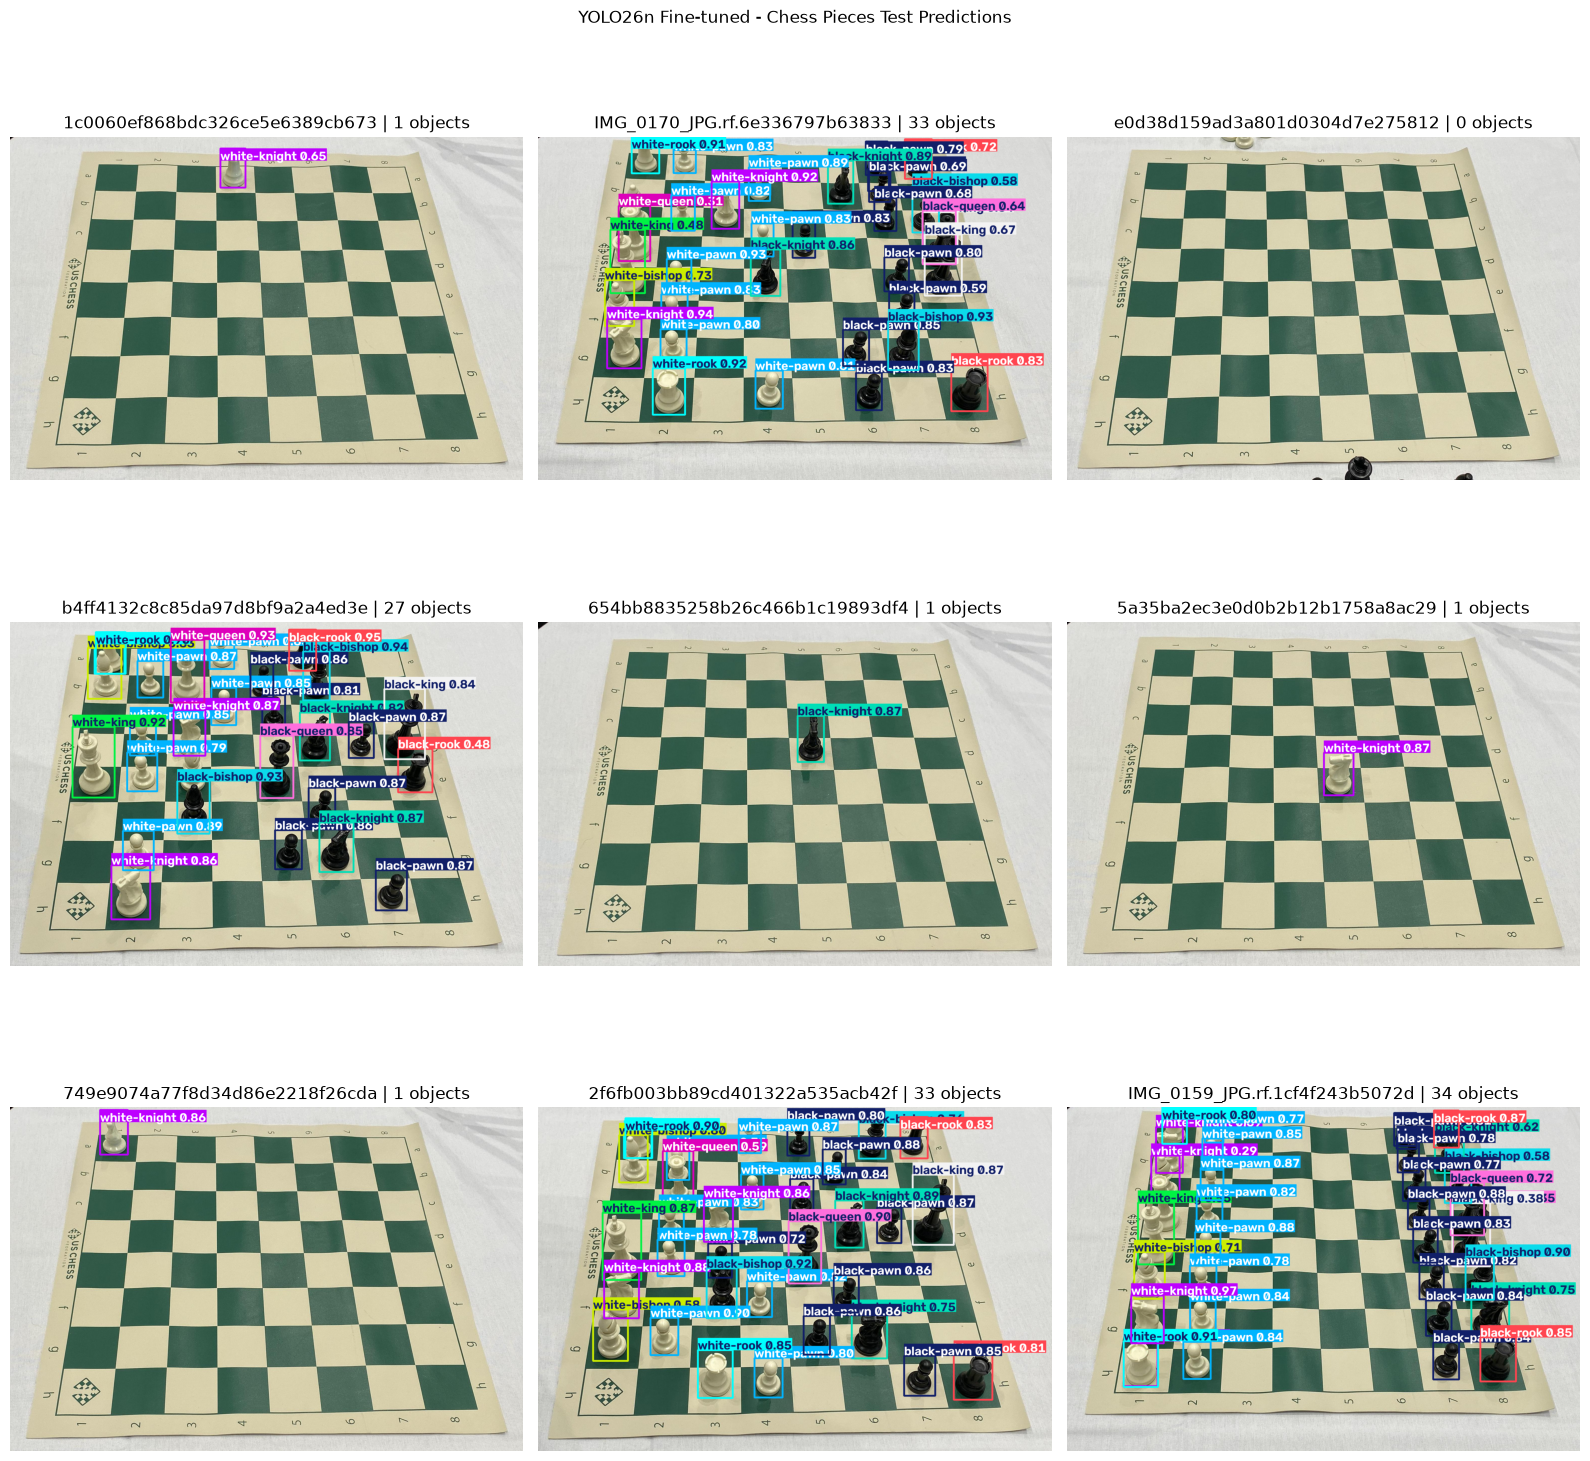

In [26]:
images = [
    p for p in (DATASET / "test/images").iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

samples = random.Random(0).sample(images, min(9, len(images)))
results = model.predict(
    source=[str(p) for p in samples],
    imgsz=416,
    conf=0.25,
    verbose=False,
)

fig, axes = plt.subplots(3, 3, figsize=(16, 16))

for ax, image, result in zip(axes.flat, samples, results):
    ax.imshow(result.plot()[:, :, ::-1])
    ax.set_title(f"{image.name[:30]} | {len(result.boxes)} objects")
    ax.axis("off")

for ax in axes.flat[len(results):]:
    ax.axis("off")

plt.suptitle("YOLO26n Fine-tuned - Chess Pieces Test Predictions")
plt.tight_layout()
plt.show()

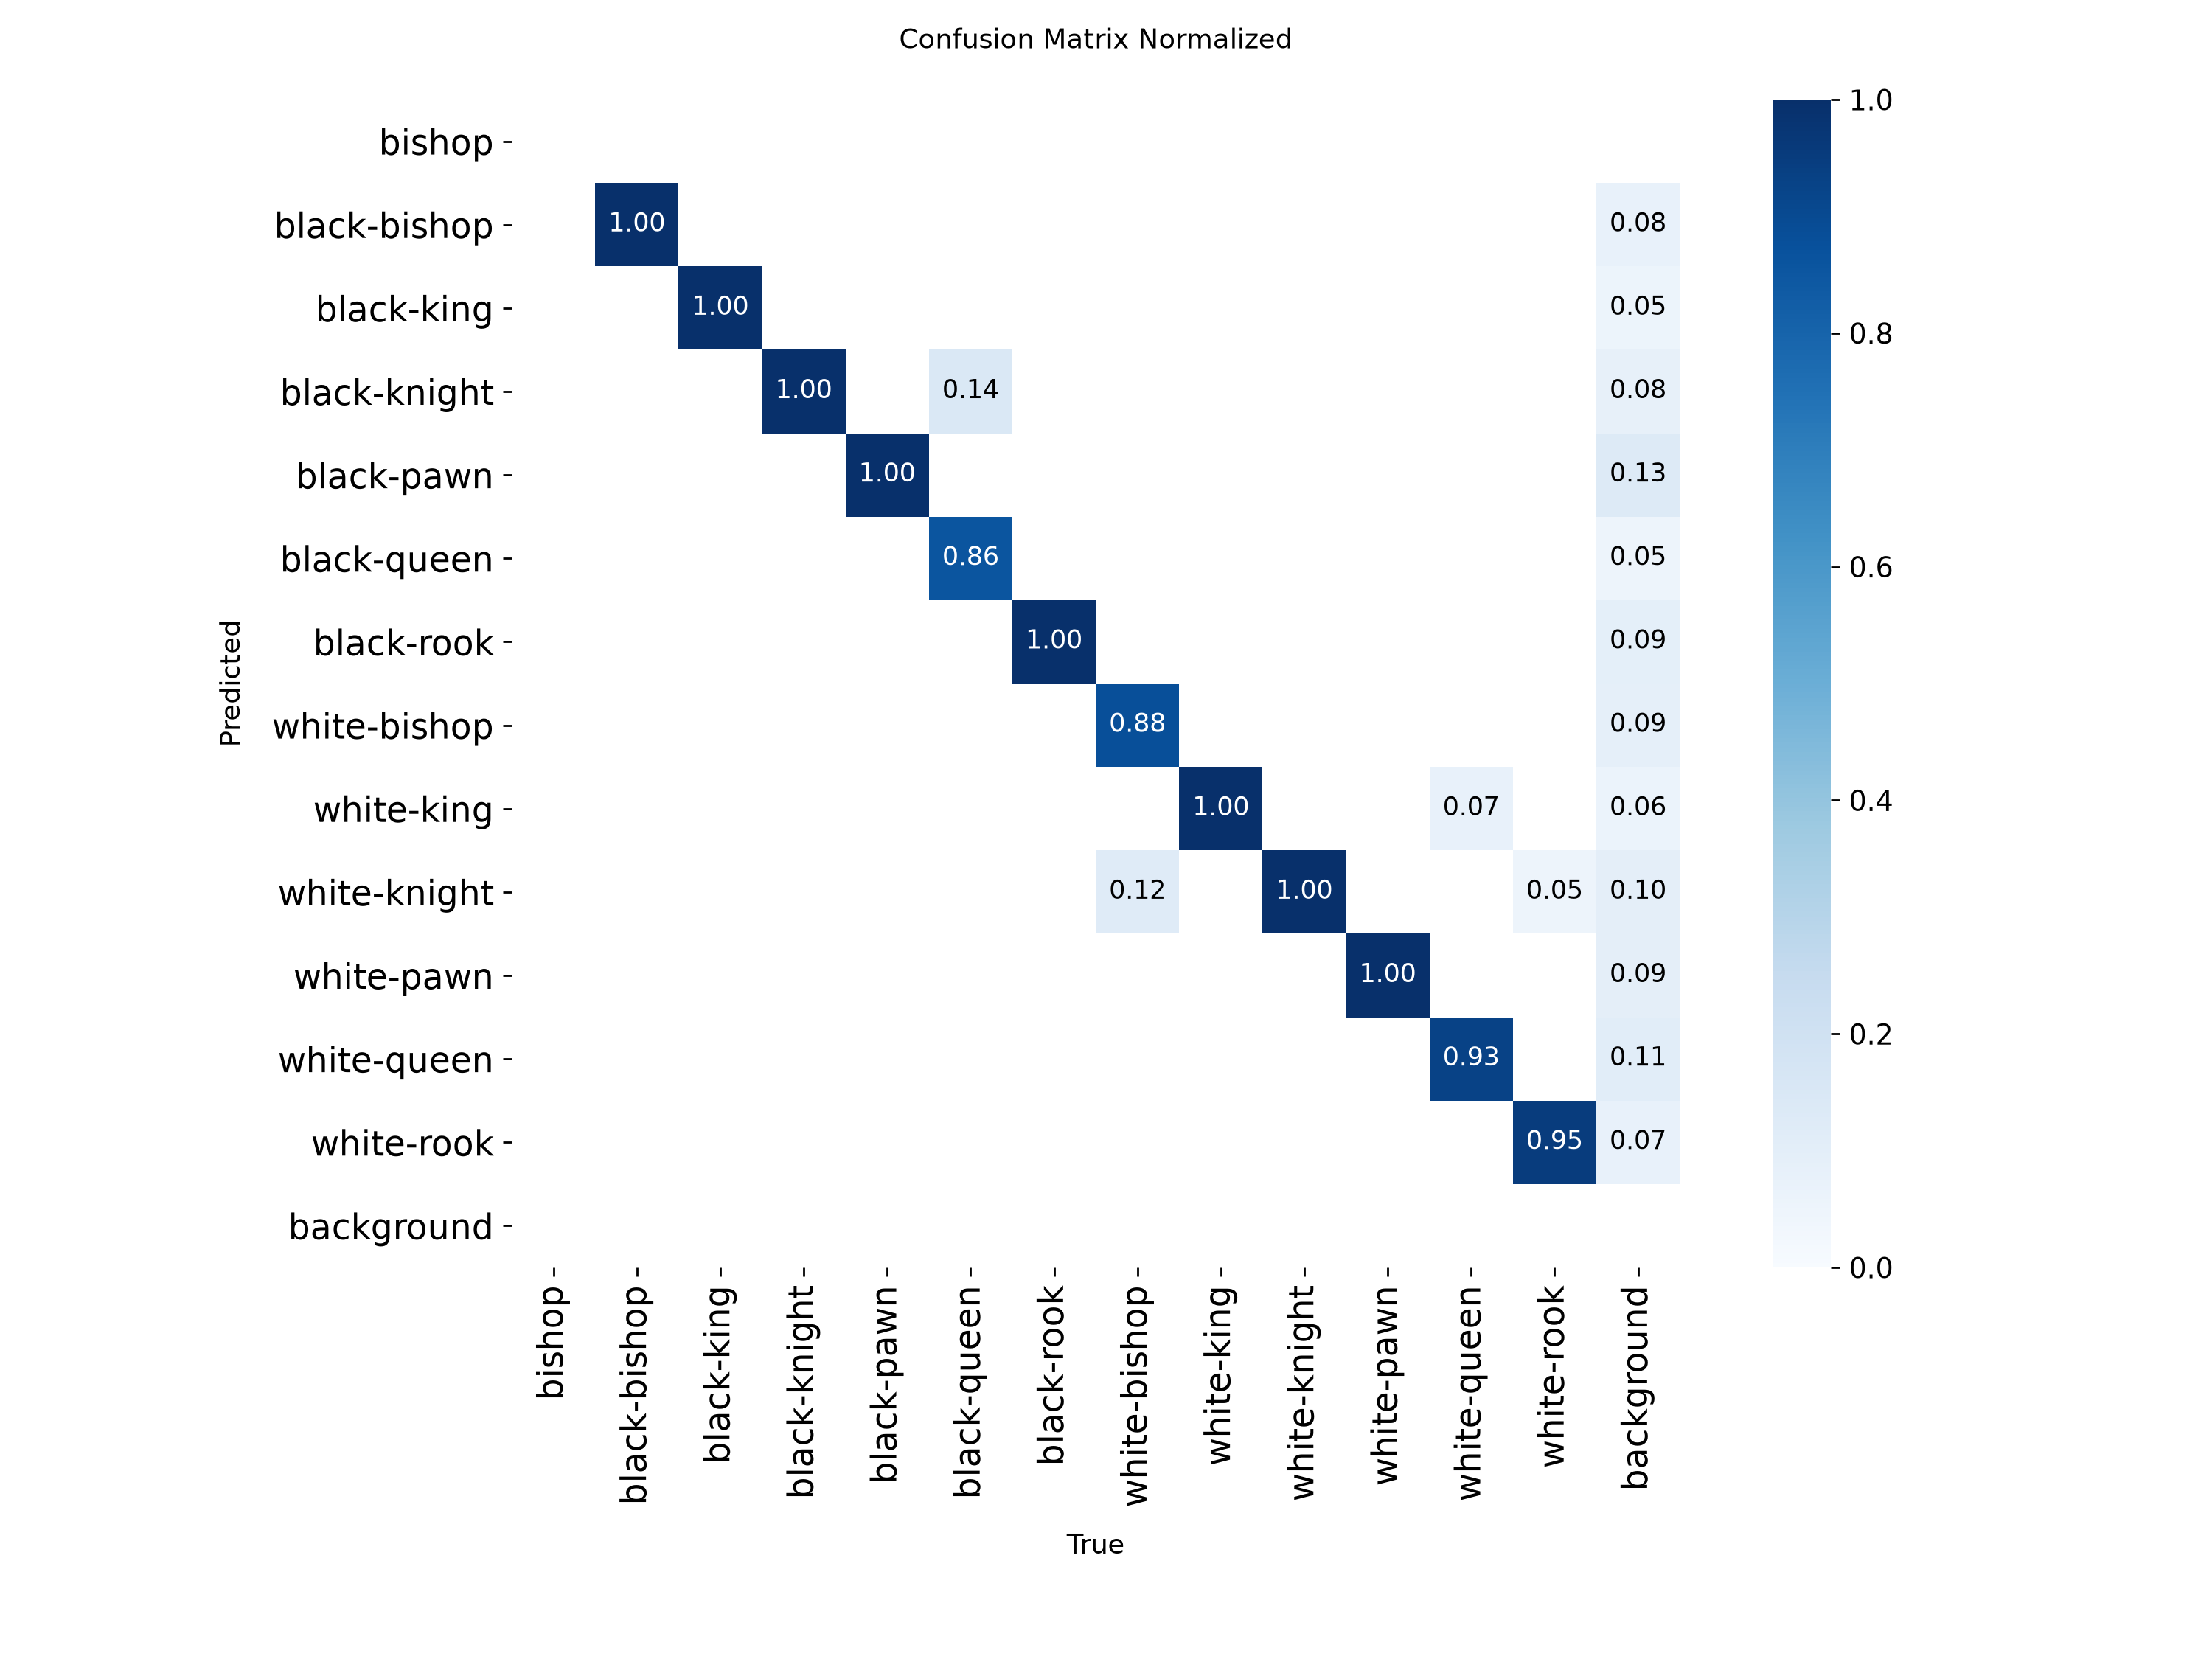

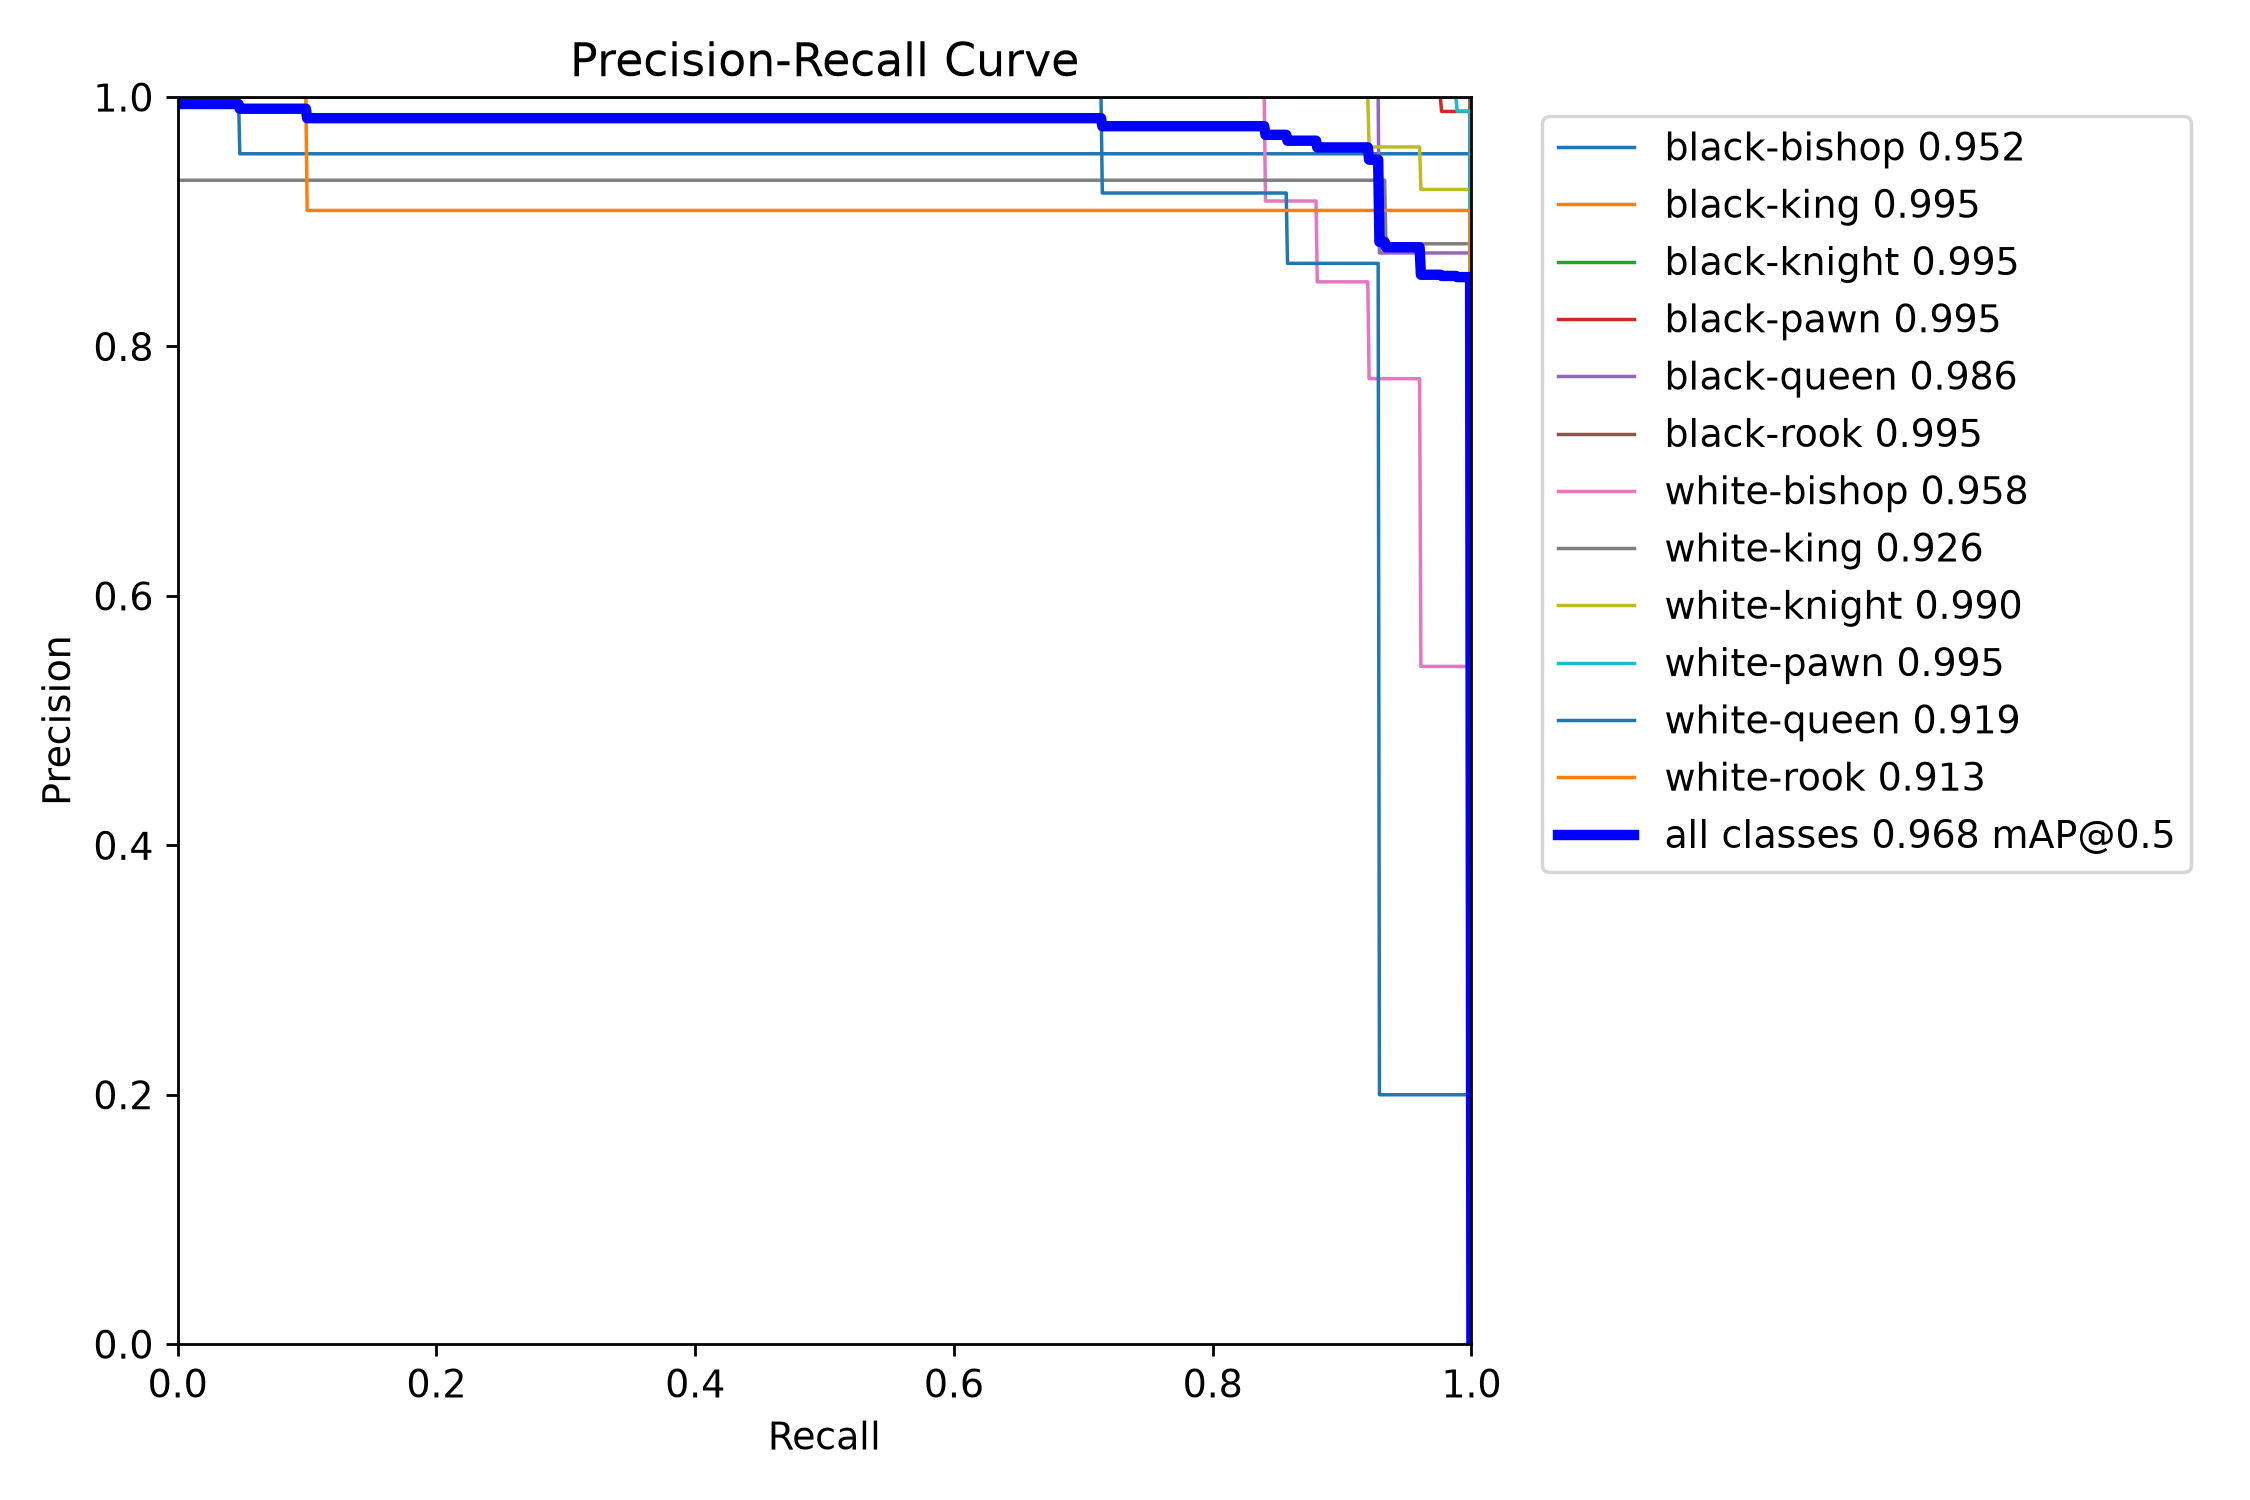

In [27]:
from IPython.display import Image

run_dir = Path(metrics.save_dir)

for name in ["confusion_matrix_normalized.png", "BoxPR_curve.png"]:
    path = run_dir / name
    if path.exists():
        display(Image(filename=str(path), width=850))

### Nhận xét kết quả Fine-tuning

- Training Convergence: YOLO26n được huấn luyện trong 50 epochs, với checkpoint tốt nhất tại epoch 40. Training và validation loss có xu hướng giảm, trong khi Precision, Recall và mAP cải thiện. Chưa thấy dấu hiệu overfitting rõ rệt.
- Validation: Mô hình đạt Precision 96.8%, Recall 94.8%, mAP\@0.5 98.0% và mAP\@0.5:0.95 78.1% trên 58 ảnh.
- Test: Trên 29 ảnh (376 đối tượng), mô hình đạt Precision 94.43%, Recall 95.51%, mAP\@0.5 96.83% và mAP\@0.5:0.95 78.41%.
- Error Analysis: Confusion Matrix trên test cho thấy phần lớn dự đoán tập trung trên đường chéo chính. Tuy nhiên, vẫn xuất hiện 4 trường hợp nhầm lẫn:
  - `black-queen` → `black-knight`: 14%.
  - `white-bishop` → `white-knight`: 12%.
  - `white-queen` → `white-king`: 7%.
  - `white-rook` → `white-knight`: 5%.

Kết luận: YOLO26n đạt hiệu quả phát hiện tốt sau fine-tuning trên Chess Pieces Dataset. Kết quả validation và test tương đối nhất quán, nhưng vẫn còn một số nhầm lẫn giữa các quân cờ có hình dạng tương đồng.


## 8. Nhận xét và giới hạn

### 8.1. Chất lượng phát hiện

- YOLOv4 đạt mAP\@0.5 cao hơn YOLO26n trên COCO val2017 (5.000 ảnh): 74.77% so với 55.54%, chênh lệch 19.23 điểm phần trăm.
- YOLOv4 phát hiện vật thể nhỏ tốt hơn (AP50_small: 59.30% so với 31.80%) và có Recall\@0.25 cao hơn (71.34% so với 48.48%).
- YOLO26n có Precision\@0.25 cao hơn (78.00% so với 70.61%), thể hiện sự đánh đổi giữa Precision và Recall.

### 8.2. Khả năng chống chịu (Robustness)

- Ánh sáng yếu: mAP\@0.5 suy giảm nhẹ, lần lượt 0.91% ở YOLOv4 và 2.49% ở YOLO26n.
- Che khuất: Gây suy giảm lớn nhất, lần lượt 21.66% và 22.74%.
- Vật thể nhỏ: YOLOv4 tiếp tục vượt trội về mAP\@0.5 (69.87% so với 51.73%).

Nhìn chung, che khuất là yếu tố ảnh hưởng rõ rệt nhất trong các điều kiện được khảo sát.

### 8.3. Hiệu năng suy luận

- YOLOv4 đạt latency trung bình 11.72 ms/ảnh (\~85.34 FPS).
- YOLO26n đạt 3.09 ms/ảnh (\~323.24 FPS), nhanh hơn khoảng 3.79 lần.

YOLOv4 có ưu thế về chất lượng phát hiện, trong khi YOLO26n phù hợp hơn với các ứng dụng ưu tiên tốc độ xử lý.

### 8.4. Kết quả Fine-tuning YOLO26n

- YOLO26n được fine-tune trên Chess Pieces Dataset trong 50 epochs với checkpoint tốt nhất tại epoch 40.
- Validation: Trên 58 ảnh (386 đối tượng), đạt Precision 96.8%, Recall 94.8%, mAP\@0.5 98.0% và mAP\@0.5:0.95 78.1%.
- Test: Trên 29 ảnh (376 đối tượng), đạt Precision 94.43%, Recall 95.51%, mAP\@0.5 96.83% và mAP\@0.5:0.95 78.41%.
- Training và validation loss giảm ổn định, chưa xuất hiện dấu hiệu overfitting rõ rệt. Kết quả validation và test tương đối nhất quán.
- Confusion Matrix trên test ghi nhận một số nhầm lẫn: `black-queen` → `black-knight` (14%), `white-bishop` → `white-knight` (12%), `white-queen` → `white-king` (7%) và `white-rook` → `white-knight` (5%).
- Không so sánh trực tiếp kết quả Chess Pieces với COCO do khác biệt về dữ liệu và số lớp.

### 8.5. Giới hạn

- Thử nghiệm robustness chỉ sử dụng 60 ảnh với các điều kiện biến đổi mô phỏng.
- Hai mô hình sử dụng pipeline tiền xử lý và suy luận khác nhau, ảnh hưởng đến tính công bằng của phép so sánh.
- Benchmark chưa tính thời gian đọc ảnh từ ổ đĩa và hiển thị.

### 8.6. Kết luận

Thực nghiệm cho thấy YOLOv4 vượt trội về mAP và Recall, đặc biệt với vật thể nhỏ, trong khi YOLO26n có ưu thế đáng kể về tốc độ và Precision trên COCO val2017. Cả hai mô hình đều bị ảnh hưởng đáng kể bởi hiện tượng che khuất.

Ngoài ra, fine-tuning YOLO26n trên Chess Pieces đạt mAP\@0.5 = 96.83% trên tập test, cho thấy khả năng thích nghi tốt với bài toán phát hiện đối tượng chuyên biệt. Tuy nhiên, vẫn tồn tại một số lỗi phân loại giữa các quân cờ có hình dạng tương đồng.


### Tài liệu tham khảo

- [YOLOv4/Darknet](https://github.com/AlexeyAB/darknet)
- [YOLO26 - Ultralytics](https://docs.ultralytics.com/models/yolo26/)
- [COCO Dataset](https://cocodataset.org/#download)
- [COCO Evaluation API](https://github.com/cocodataset/cocoapi)
- [Chess Pieces Dataset - Roboflow Universe (Version 23)](https://universe.roboflow.com/joseph-nelson/chess-pieces-new/dataset/23)